In [14]:
#!/usr/bin/env python
# coding: utf-8
"""
Generate ICs for GENGA with a piecewise disk:
- Sigma(1 AU) = 8 g/cm^2
- Outer (0.7–2 AU): Sigma ∝ a^(-3/2)
- Inner taper (0.3–0.7 AU): linear ramp from 0 at 0.3 to Sigma(0.7 AU) at 0.7


We sample semi-major axes from p(a) ∝ a * Sigma(a) (annulus area factor!).
This replaces previous samplers that did not include the area factor or the
piecewise taper correctly.


Output format (for param.dat):
Input file Format: << m a e inc O w M >>
Angle units: radian


Notes:
- Masses written in solar masses.
- a in AU, angles in radians.
- Do NOT include the star in this file; set it in param.dat.
"""


import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm

In [15]:
#!/usr/bin/env python
# coding: utf-8
"""
Generate ICs for GENGA with a piecewise disk:
- Sigma(1 AU) = 8 g/cm^2
- Outer (0.7–2 AU): Sigma ∝ a^(-3/2)
- Inner taper (0.3–0.7 AU): linear ramp from 0 at 0.3 to Sigma(0.7 AU) at 0.7


We sample semi-major axes from p(a) ∝ a * Sigma(a) (annulus area factor!).
This replaces previous samplers that did not include the area factor or the
piecewise taper correctly.


Output format (for param.dat):
Input file Format: << m a e inc O w M >>
Angle units: radian


Notes:
- Masses written in solar masses.
- a in AU, angles in radians.
- Do NOT include the star in this file; set it in param.dat.
"""


import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm

In [16]:
# -------------------------------------------------------------
# Constants (only used for plotting surface density)
# -------------------------------------------------------------
Sigma1 = 8.0 # g/cm^2 at 1 AU
AU_cm = (1 * u.AU).to(u.cm).value

In [17]:
# -------------------------------------------------------------
# Disk definition
# -------------------------------------------------------------
A_INNER_MIN, A_BREAK, A_OUTER_MAX = 0.3, 0.7, 2.0




def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)




def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

In [18]:
# -------------------------------------------------------------
# Region mass split (fractions only; common factors cancel)
# -------------------------------------------------------------


def mass_split(a_in_min=A_INNER_MIN, a_break=A_BREAK, a_out_max=A_OUTER_MAX):
    # Inner: p(a) ∝ a * Sigma_inner(a) ∝ a(a-0.3)
    F = lambda x: (x**3)/3.0 - 0.15*(x**2)
    Sbreak = sigma_out(a_break)
    M_in_unnorm = (Sbreak / (a_break - a_in_min)) * (F(a_break) - F(a_in_min))
    # Outer: p(a) ∝ a * Sigma_out(a) ∝ a^(-1/2)
    M_out_unnorm = Sigma1 * (2.0 * (np.sqrt(a_out_max) - np.sqrt(a_break)))
    Mtot = M_in_unnorm + M_out_unnorm
    return M_in_unnorm / Mtot, M_out_unnorm / Mtot




# Precompute region selection probability
P_INNER, P_OUTER = mass_split()

In [19]:
# -------------------------------------------------------------
# Inverse-CDF samplers in each region
# -------------------------------------------------------------

def _inv_cdf_outer(u):
    """Outer region a∈[0.7,2.0], p(a) ∝ a^(-1/2)."""
    amin, amax = A_BREAK, A_OUTER_MAX
    return (u * (np.sqrt(amax) - np.sqrt(amin)) + np.sqrt(amin)) ** 2


def _inv_cdf_inner(u):
    """Inner region a∈[0.3,0.7], p(a) ∝ a(a-0.3); invert cubic CDF by Newton."""
    amin, amax = A_INNER_MIN, A_BREAK
    F = lambda x: (x**3) / 3.0 - 0.15 * (x**2)
    Fmin, Fmax = F(amin), F(amax)
    target = Fmin + u * (Fmax - Fmin)
    # good initial guess
    x = amin + (amax - amin) * u
    for _ in range(50):
        Fx = (x**3) / 3.0 - 0.15 * (x**2)
        dFx = x**2 - 0.3 * x
        step = (Fx - target) / max(dFx, 1e-14)
        x -= step
        if x < amin:
            x = 0.5 * (x + amin)
        if x > amax:
            x = 0.5 * (x + amax)
        if abs(step) < 1e-12:
            break
    return x


def sample_a_from_disk(size=1, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    u = rng.random(size)
    a = np.empty(size)
    inner_mask = (u < P_INNER)
    n_inner = inner_mask.sum()
    n_outer = size - n_inner
    if n_inner > 0:
        a[inner_mask] = np.array([_inv_cdf_inner(ui) for ui in rng.random(n_inner)])
    if n_outer > 0:
        a[~inner_mask] = _inv_cdf_outer(rng.random(n_outer))
    return a if size != 1 else a[0]

In [20]:
# -------------------------------------------------------------
# Surface-density estimator for diagnostics
# -------------------------------------------------------------

def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma


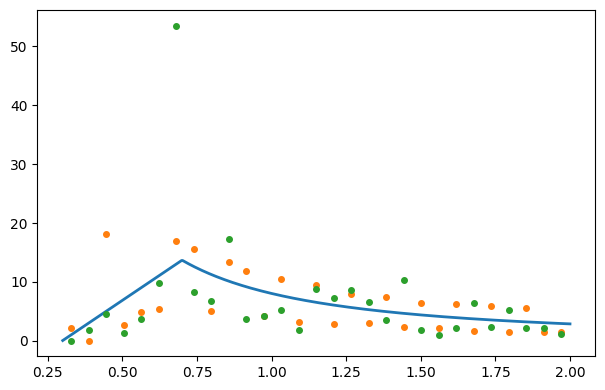

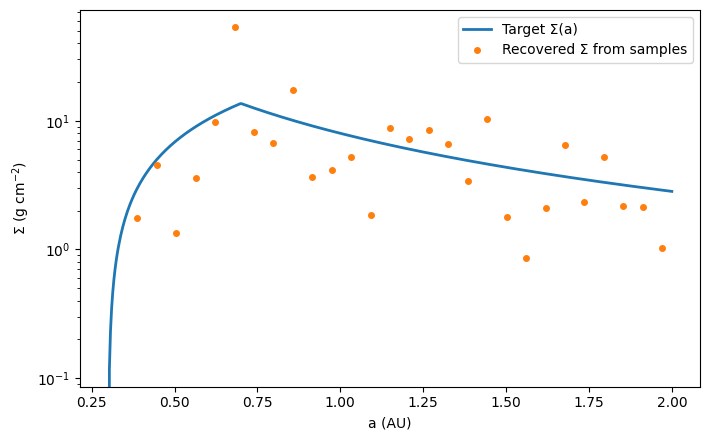

In [21]:
# -------------------------------------------------------------
# Example: Chambers-like setup
# -------------------------------------------------------------
# total mass and counts
#Mtot_sol = 2.604/2 * (u.M_earth.to(u.solMass))  # total solids in solar masses
N = 280
m_pl_sol = 2.8e-8
m_pl_g = m_pl_sol * u.solMass.to(u.g)

# sample semi-major axes from disk
rng = np.random.default_rng(42)
a_samples_pl = sample_a_from_disk(size=int(N/2), rng=rng)
a_samples_pl = np.sort(a_samples_pl)
np.savetxt("semi_major_axes/cham_bimodal_pl_samples_sep3.txt", a_samples_pl)

a_samples_embs = sample_a_from_disk(size=int(N/2/10),rng=rng)
a_samples_embs = np.sort(a_samples_embs)
np.savetxt("semi_major_axes/cham_bimodal_emb_samples_sep3.txt", a_samples_embs)
a_samples_emb_repeat = np.repeat(a_samples_embs, 10, axis=0)
a_samples_all = np.concatenate([a_samples_emb_repeat, a_samples_pl])
a_samples_all = np.sort(a_samples_all)

np.savetxt("semis_chambers_to_check.txt", a_samples_all)

# Diagnostics plot: recovered surface density vs target laws
centers, sigma_est = compute_surface_density(a_samples_all, m_pl_g, bins=np.linspace(0.3, 2.0, 30))

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))

plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers, sigma_est, "o", ms=4, label="Recovered Σ from samples")
plt.yscale("log")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()
# plt.savefig("surface_density_check.png", dpi=160)
# print("Saved surface_density_check.png")


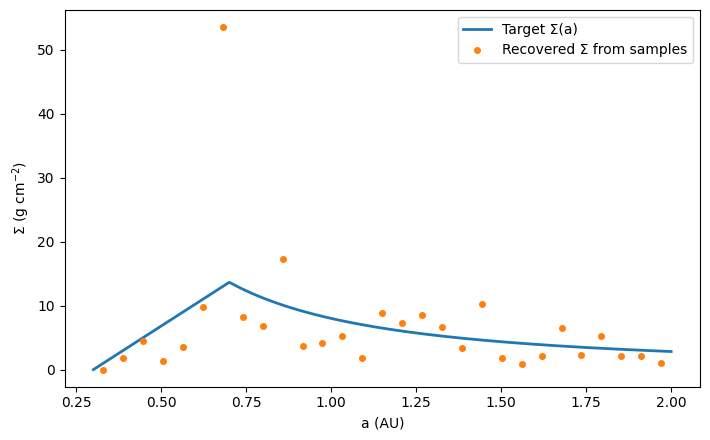

In [22]:
plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers, sigma_est, "o", ms=4, label="Recovered Σ from samples")
plt.yscale("linear")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()

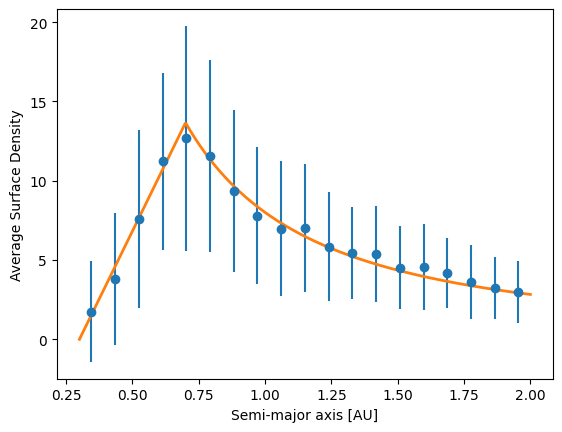

In [23]:
# Run with different seeds
N = 280
m_pl_sol = 2.8e-8
m_pl_g = m_pl_sol * u.solMass.to(u.g)

def generate_a_samples_chambers(rand_seed):
    rng = np.random.default_rng(rand_seed)
    samples_pl = sample_a_from_disk(size=int(N/2), rng=rng)
    samples_pl = np.sort(samples_pl)
    #np.savetxt("semi_major_axes/cham_bimodal_pl_samples.txt", a_samples_pl)

    samples_embs = sample_a_from_disk(size=int(N/2/10),rng=rng)
    samples_embs = np.sort(samples_embs)
    #np.savetxt("semi_major_axes/cham_bimodal_emb_samples.txt", a_samples_embs)
    samples_emb_repeat = np.repeat(samples_embs, 10, axis=0)
    samples_all = np.concatenate([samples_emb_repeat, samples_pl])
    samples_all = np.sort(samples_all) 
    return samples_all 

n_runs = 100
bins = np.linspace(0.3, 2, 20)

all_surface_densities = []


for seed in range(n_runs):
    samples_all = generate_a_samples_chambers(seed)
    bin_centers, surface_density = compute_surface_density(samples_all, m_pl_g, bins=bins)
    all_surface_densities.append(surface_density)

# Convert to numpy array for averaging
all_surface_densities = np.array(all_surface_densities)  # shape = (n_runs, n_bins)

# Average across runs
avg_surface_density = np.mean(all_surface_densities, axis=0)
std_surface_density = np.std(all_surface_densities, axis=0)

# Now you can plot or analyze
import matplotlib.pyplot as plt
plt.errorbar(bin_centers, avg_surface_density, yerr=std_surface_density, fmt='o')
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.xlabel("Semi-major axis [AU]")
plt.ylabel("Average Surface Density")
plt.show()

In [24]:
for i in np.arange(len(Sig)):
    if (np.abs(a[i] - 1.0) < 0.005) or (np.abs(a[i] - 2.0) < 0.005):
        print(a[i], Sig[i])

0.9983967935871743 8.019277103258037
1.001803607214429 7.978405405944715
1.9965931863727455 2.835669486469919
2.0 2.8284271247461903


In [25]:
import numpy as np

def validate_semimajor_axes(path, disk_edges=(0.3, 2.0)):
    """
    Validate a file containing only semi-major axis values (AU).
    
    Parameters
    ----------
    path : str
        Path to the text file with semi-major axes (one per line).
    disk_edges : tuple(float, float)
        Allowed range for semi-major axes in AU (min, max).
    
    Returns
    -------
    list of str
        Issues found in the file. Empty if everything is valid.
    """
    issues = []
    try:
        a = np.loadtxt(path)
    except Exception as e:
        return [f"Failed to read file: {e}"]

    # Ensure it's a 1D array
    if a.ndim > 1:
        issues.append("File should contain only one column of semi-major axes.")

    # Flatten
    a = np.ravel(a)

    if a.size == 0:
        issues.append("File has zero entries.")

    if np.any(~np.isfinite(a)):
        issues.append("NaN/Inf detected in semi-major axes.")

    if np.any((a < disk_edges[0]) | (a > disk_edges[1])):
        issues.append(f"Semi-major axes outside [{disk_edges[0]}, {disk_edges[1]}] AU")

    return issues

# Example usage:
# problems = validate_semimajor_axes("a_values.txt", disk_edges=(0.5, 1.0))
# if problems:
#     print("Problems:\n - " + "\n - ".join(problems))
# else:
#     print("All semi-major axes look valid.")


In [26]:
problems = validate_semimajor_axes("semis_chambers_to_check.txt")

In [27]:
if problems: 
    print("Problems:\n - " + "\n - ".join(problems))
else:
    print("Looks OK.")

Looks OK.


# Original Chambers Data

Wrote initial_chambers_2.8e+02_pls.dat


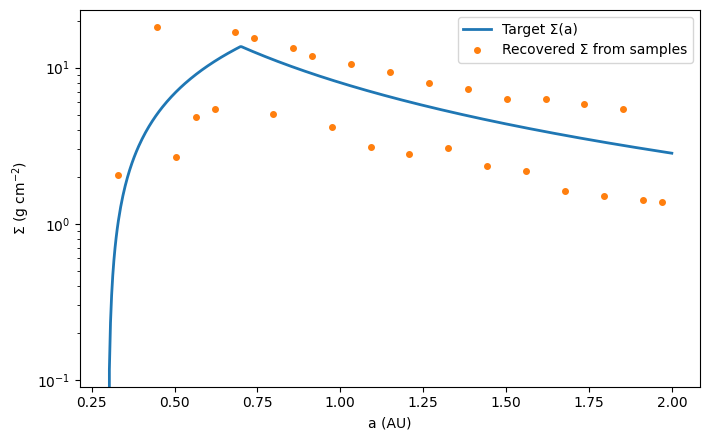

In [28]:
chambers_original_embs = np.loadtxt("semi_major_axes/original_chambers_2013_emb_semis.txt")
chambers_original_pls = np.loadtxt("semi_major_axes/original_chambers_2013_pl_semis.txt")

# -------------------------------------------------------------
# Example: Chambers-like setup
# -------------------------------------------------------------
# total mass and counts
#Mtot_sol = 2.604/2 * (u.M_earth.to(u.solMass))  # total solids in solar masses
N = 280
m_pl_sol = 2.8e-8
m_pl_g = m_pl_sol * u.solMass.to(u.g)

# sample semi-major axes from disk
rng = np.random.default_rng(42)
a_samples_pl = chambers_original_pls
a_samples_embs = chambers_original_embs
a_samples_emb_repeat = np.repeat(a_samples_embs, 10, axis=0)
a_samples_all = np.concatenate([a_samples_emb_repeat, a_samples_pl])
a_samples_all = np.sort(a_samples_all)
# other orbital elements
inc = rng.uniform(0.0, 0.0175, N)          # rad
ecc = rng.uniform(0.0, 0.01, N)
Omega = rng.uniform(0.0, 2*np.pi, N)       # longitude of ascending node
omega = rng.uniform(0.0, 2*np.pi, N)       # argument of periapsis
Mmean = rng.uniform(0.0, 2*np.pi, N)       # mean anomaly

# build output array: < m a e inc O w M >
out = np.column_stack([
    np.full(N, m_pl_sol, dtype=float),
    a_samples_all,
    ecc,
    inc,
    Omega,
    omega,
    Mmean,
])

fname = f"initial_chambers_{N:.1e}_pls.dat"
np.savetxt(fname, out, fmt="%.10e")
#np.savetxt("semis_pl_chambers_sep1.txt", a_samples_all)
print(f"Wrote {fname}")

# Diagnostics plot: recovered surface density vs target laws
centers_chambers, sigma_est_chambers = compute_surface_density(a_samples_all, m_pl_g, bins=np.linspace(0.3, 2.0, 30))

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))

plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers_chambers, sigma_est_chambers, "o", ms=4, label="Recovered Σ from samples")
plt.yscale("log")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()
# plt.savefig("surface_density_check.png", dpi=160)
# print("Saved surface_density_check.png")


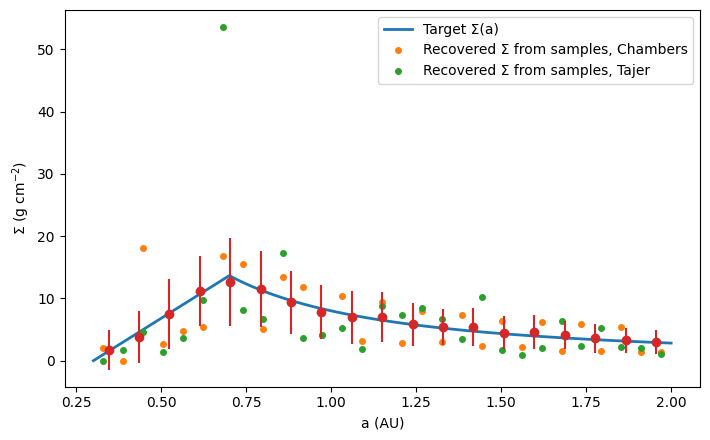

In [29]:
plt.figure(figsize=(7.2, 4.5))
plt.plot(a, Sig, lw=2, label="Target Σ(a)")
plt.plot(centers_chambers, sigma_est_chambers, "o", ms=4, label="Recovered Σ from samples, Chambers")
plt.plot(centers, sigma_est, "o", ms=4, label="Recovered Σ from samples, Tajer")
plt.errorbar(bin_centers, avg_surface_density, yerr=std_surface_density, fmt='o')
plt.yscale("linear")
plt.xlabel("a (AU)")
plt.ylabel(r"Σ (g cm$^{-2}$)")
plt.legend()
plt.tight_layout()
plt.show()